##**1. 실습코드 00**

: ITK-SNAP으로 day15를 day0에 registration을 진행한 결과파일을 불러와서 같은 단면을 day0, day15에 대해 display하여 비교하기.

In [135]:
!pip install nibabel

In [136]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [137]:
imgpath = '/content/drive/MyDrive/Medical image processing/HW 01/'
os.listdir(imgpath)

['Blurring image.jpg',
 'grayscale.jpg',
 'volume-covid19-A-0700_day015-reg_to_day000.nii.gz',
 'volume-covid19-A-0700_day000.nii.gz',
 'volume-covid19-A-0700_day015.nii.gz']

In [138]:
import nibabel as nib

In [139]:
h = nib.load(imgpath+'volume-covid19-A-0700_day000.nii.gz')
print(h.shape)

(512, 512, 70)


In [140]:
print(h.header)

<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : b''
db_name         : b''
extents         : 0
session_error   : 0
regular         : b'r'
dim_info        : 0
dim             : [  3 512 512  70   1   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : int16
bitpix          : 16
slice_start     : 0
pixdim          : [1.   0.74 0.74 5.   0.   0.   0.   0.  ]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : unknown
xyzt_units      : 2
cal_max         : 0.0
cal_min         : 0.0
slice_duration  : 0.0
toffset         : 0.0
glmax           : 0
glmin           : 0
descrip         : b''
aux_file        : b''
qform_code      : scanner
sform_code      : unknown
quatern_b       : 0.0
quatern_c       : 0.0
quatern_d       : 1.0
qoffset_x       : 207.63699340820312
qoffset_y       : 189.08309936523438
qoffset_z       : -1019.5
srow_x

In [141]:
ct_base = h.get_fdata()
print(ct_base.dtype, ct_base.shape)
print(np.min(ct_base),np.max(ct_base))

float64 (512, 512, 70)
-5363.0 30689.0


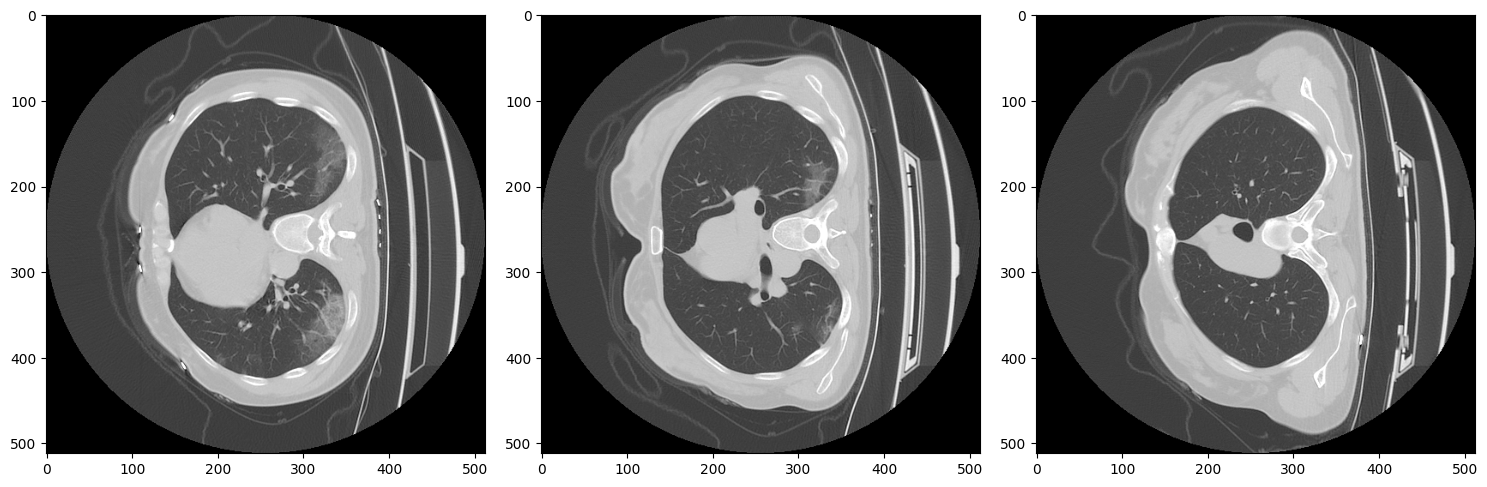

In [142]:
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(ct_base[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(132)
plt.imshow(ct_base[:,:,40],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(133)
plt.imshow(ct_base[:,:,50],vmin=-1500,vmax=500,cmap='gray')
plt.tight_layout()
plt.show()

- day015 및 day015를 day000에 registration한 파일을 각각 불러오기.
- day000을 포함하여 세 ct영상데이터의 동일한 단면을 display하여 비교하기.

In [143]:
ct_FU = nib.load(imgpath+'volume-covid19-A-0700_day015.nii.gz').get_fdata()
ct_FU_reg = nib.load(imgpath+'volume-covid19-A-0700_day015-reg_to_day000.nii.gz').get_fdata()

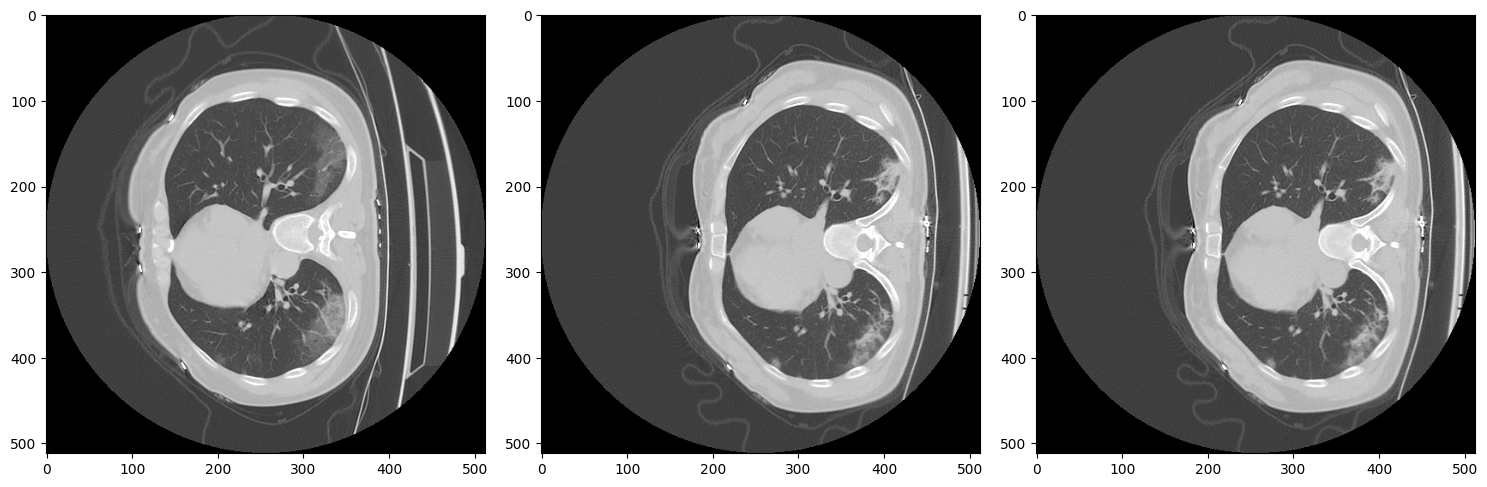

In [144]:
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(ct_base[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(132)
plt.imshow(ct_FU[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(133)
plt.imshow(ct_FU_reg[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.tight_layout()
plt.show()

##**2. 실습코드 01**

: Exercise 1. local histogram equalization을 통해 숨겨진 패턴 확인하기

In [145]:
import numpy as np
import matplotlib.pyplot as plt
import os

### Exercise 1.
- 아래의 예는 local histogram equalization을 수행한다.
- 적절한 neighborhood size N을 찾아서 숨겨진 기호들을 모두 확인해보자.
- plt.imshow의 vim, vmax를 수정하여서도 숨겨진 기호들을 확인할 수 있으나, 본 실습에서는 vmax=255로 고정하여 histogram processing을 통해 숨겨진 기호들을 확인하자.

In [165]:
f = plt.imread('/content/drive/MyDrive/Medical image processing/DIP4E/DIP4E/hidden-symbols.tif')
print(f.shape,f.dtype)

(256, 256) uint8


In [166]:
def histogram_equalization(image):
    histogram, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
    cdf = histogram.cumsum()
    cdf_min = cdf.min()
    cdf_max = cdf.max()
    cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_normalized = cdf_normalized.astype(np.uint8)
    equalized_image = cdf_normalized[image]
    return equalized_image

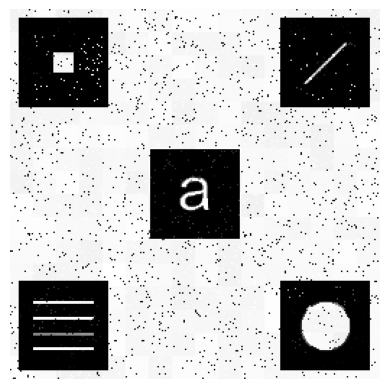

In [170]:
N = 16
f_eq_local = np.zeros_like(f)

for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()


##**3. 실습코드 01**

: Exercise 2. 본인의 사진을 grayscale image로 불러온 후, 서로 다른 kernel size에 대한 LPF결과 비교

### Exercise 2.
- 직접 찍은 사진을 grayscale image로 불러와서, kernel size를 3x3, 7x7, 15x15, 30x30 으로 늘려가며 box kernel을 정의하여 LPF를 진행한 결과를 출력하고 kernel size에 따른 연산시간의 차이를 확인하자.

In [149]:
import scipy.signal as signal
from skimage import io

In [150]:
f = io.imread(imgpath+'/grayscale.jpg',as_gray=True)

print(f.shape,f.dtype)

(3328, 2252) float64


In [151]:
import time

computation time =  0.38111448287963867  sec


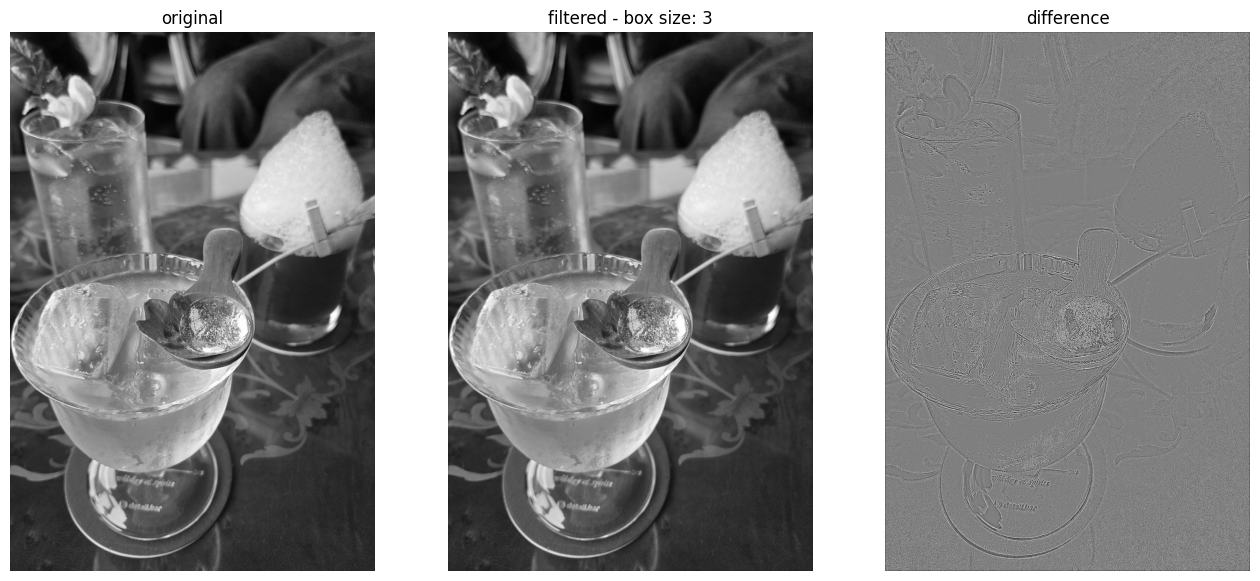

computation time =  5.111953258514404  sec


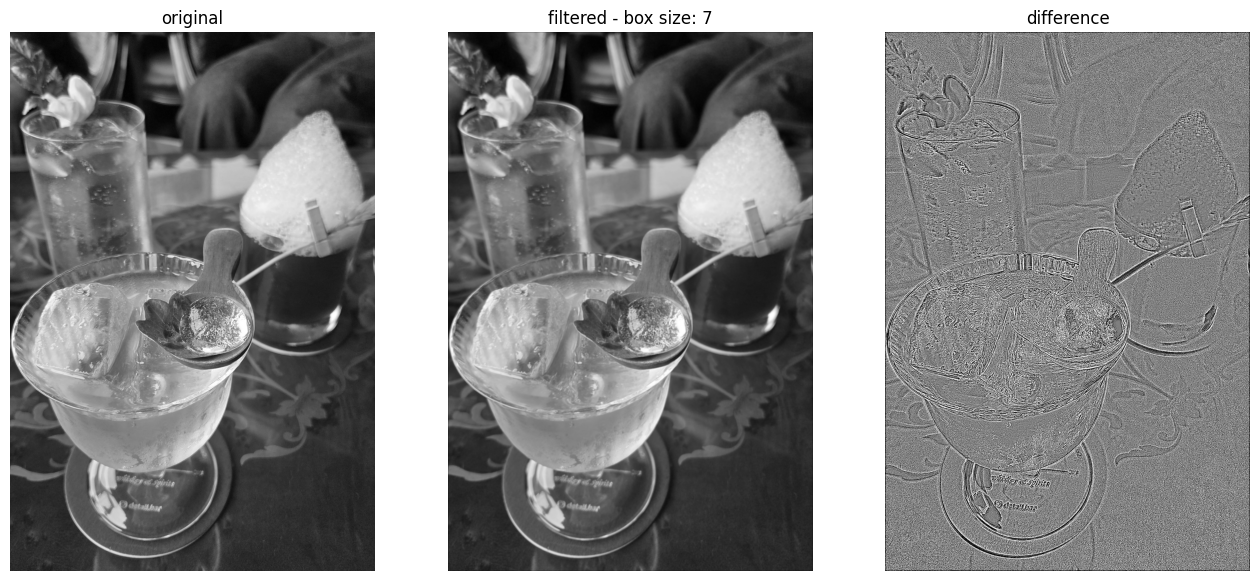

computation time =  5.650745153427124  sec


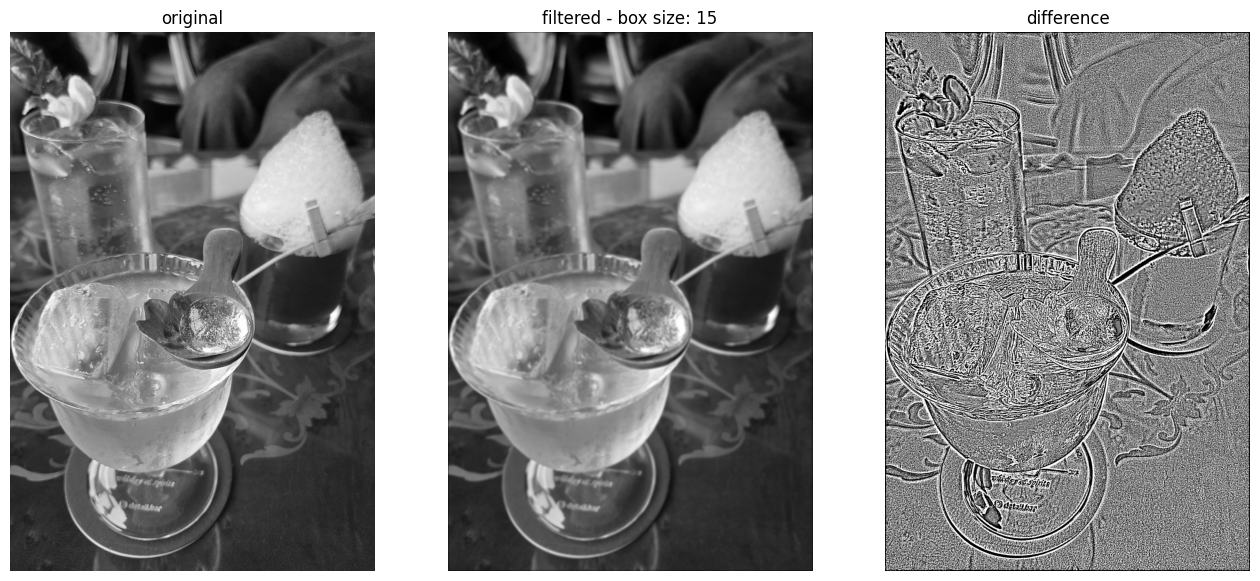

computation time =  16.851012229919434  sec


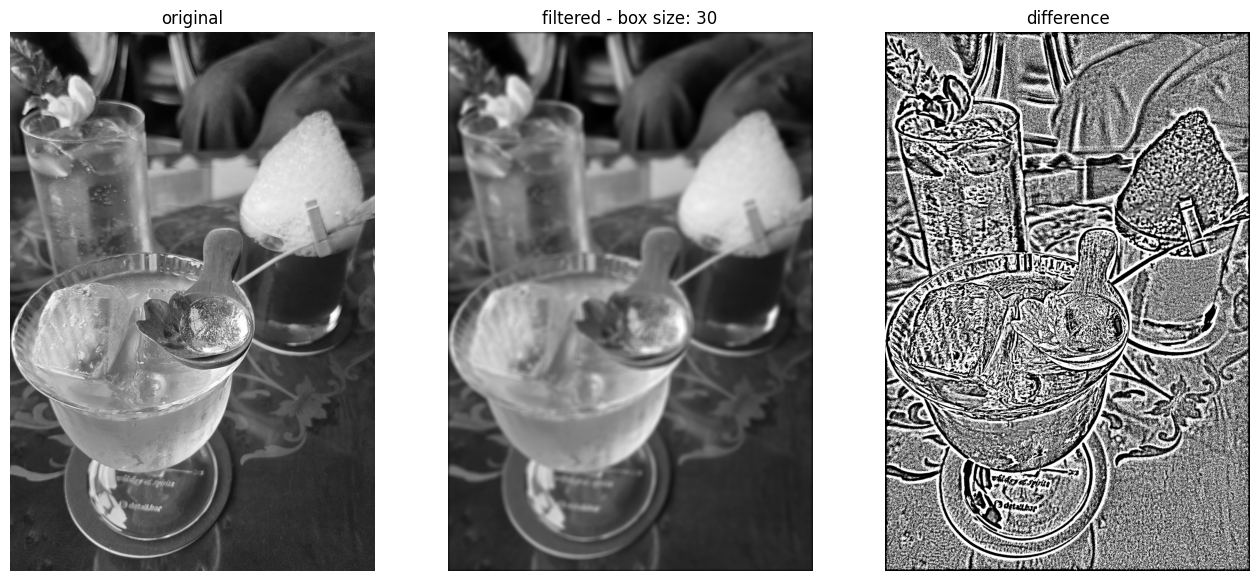

In [152]:
for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  s0 = time.time()
  y_b = signal.convolve2d(f,wb,mode='same')
  compu_time=time.time() - s0
  print('computation time = ', compu_time,' sec')
  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

##**4. 실습코드 01**

: Exercise 3. Blurring이 발생한 사진을 가져와서 적당한 HPF결과를 활용하여 sharpening을 진행하기

### Exercise 3.
- highpass filtering의 결과를 활용하여 blurred image를 sharp하게 개선시켜 보자.
- 자신만의 blurred image를 가져와서, Laplacian kernel을 통한 highpass filtering을 진행하고 이를 이용하여 원본영상의 sharpness를 증대시켜보자.
- w 및 c를 적절하게 변화시켜 가면서 결과를 확인하자.

(2400, 1800) float64


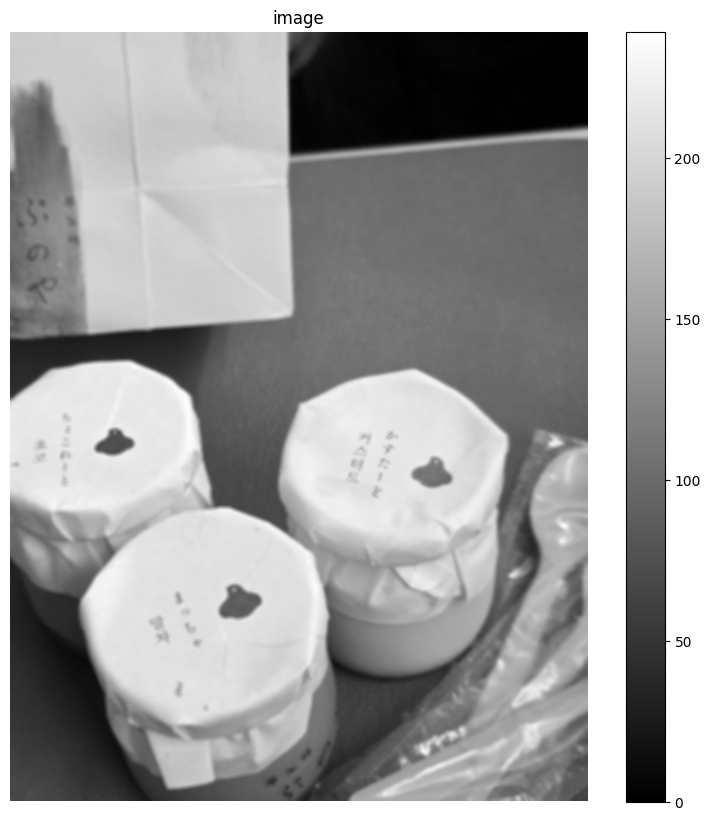

In [153]:
f = plt.imread(imgpath+'Blurring image.jpg')

if f.ndim == 3:
    f = np.mean(f, axis=2)

print(f.shape,f.dtype)
plt.figure(figsize=(10,10))
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('image')
plt.colorbar()
plt.show()

# Laplacian Kernel (2nd order diff.)

In [154]:
w1 = np.array([[0,1,0],[1,-4.,1],[0,1,0]])
w2 = np.array([[0,-1,0],[-1,4.,-1],[0,-1,0]])

w3 = np.array([[1,1,1],[1,-8.,1],[1,1,1]])
w4 = np.array([[-1,-1,-1],[-1,8.,-1],[-1,-1,-1]])

print(w1)
print(w2)
print(w3)
print(w4)

[[ 0.  1.  0.]
 [ 1. -4.  1.]
 [ 0.  1.  0.]]
[[ 0. -1.  0.]
 [-1.  4. -1.]
 [ 0. -1.  0.]]
[[ 1.  1.  1.]
 [ 1. -8.  1.]
 [ 1.  1.  1.]]
[[-1. -1. -1.]
 [-1.  8. -1.]
 [-1. -1. -1.]]


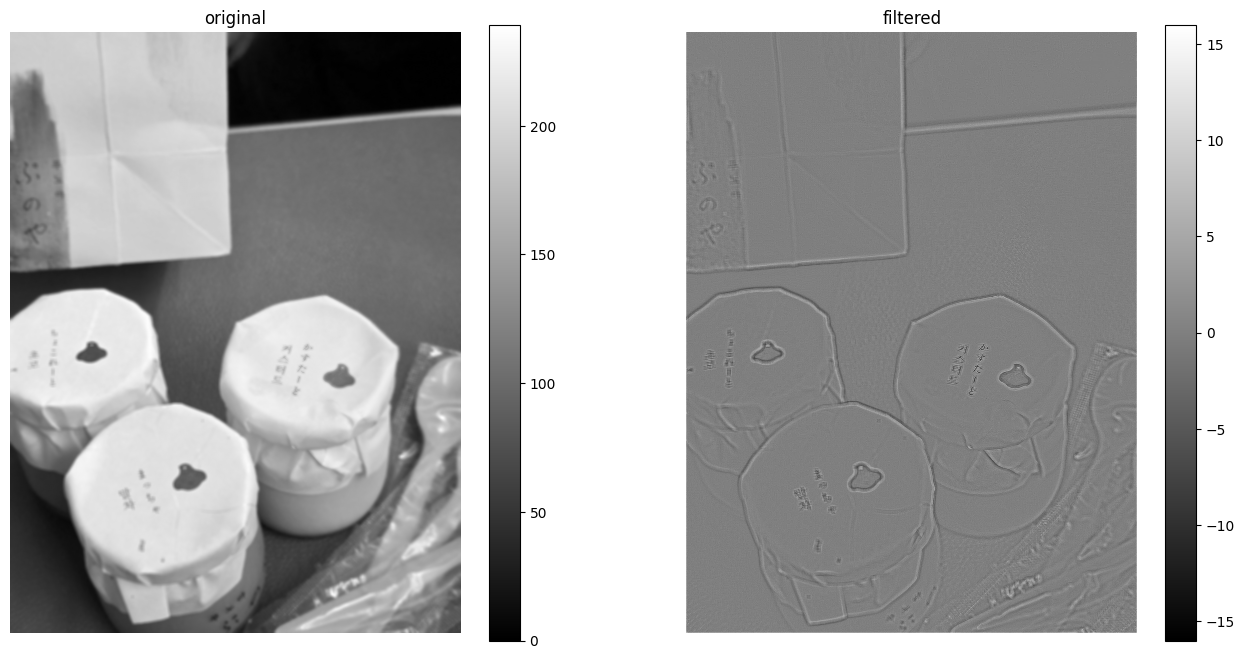

In [155]:
y = signal.convolve2d(f,w4,mode='same')
y.shape
plt.figure(figsize=(16,8))
plt.subplot(121)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(122)
plt.imshow(y,cmap='gray',vmin=-16,vmax=16)
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()

### Exercise 3.
- highpass filtering의 결과를 활용하여 blurred image를 sharp하게 개선시켜 보자.
- 자신만의 blurred image를 가져와서, Laplacian kernel을 통한 highpass filtering을 진행하고 이를 이용하여 원본영상의 sharpness를 증대시켜보자.
- w 및 c를 적절하게 변화시켜 가면서 결과를 확인하자.


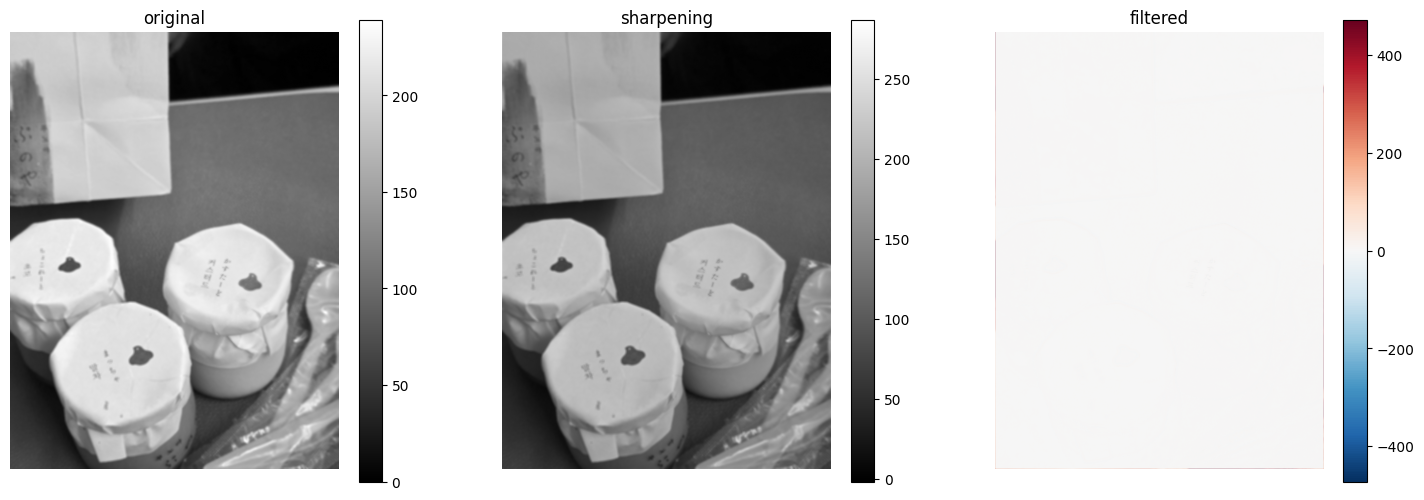

In [156]:
w = np.array([[0,-1,0],[-1,4.,-1],[0,-1,0]])
y = signal.convolve2d(f,w4,mode='same')
c = 0.095
g = f + c*(y)
plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('sharpening')
plt.subplot(133)
plt.imshow(y,cmap='RdBu_r',vmin=-0.5*np.max(np.abs(y)),vmax=0.5*np.max(np.abs(y)))
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()